# Examination Paper-Leak Analysis in India

## Project Overview

This project analyzes reported examination paper-leak incidents in India to identify patterns across time, examination types, conducting bodies, locations, and reported outcomes.

The analysis uses Python and Pandas for data preparation and exploration, along with Matplotlib for data visualization.

## Objectives

- Analyze the distribution of reported paper-leak incidents over time.
- Identify examination categories associated with reported incidents.
- Compare incidents involving state-level and central examinations.
- Examine reported arrests and convictions.
- Analyze the number of aspirants affected where data is available.
- Identify key patterns and observations from the dataset.

## Tools & Technologies

- Python
- Pandas
- NumPy
- Matplotlib
- Jupyter Notebook

## Dataset

The dataset contains reported examination paper-leak incidents in India, including information such as incident date, examination name, conducting body, examination type, location, actions taken, arrests, convictions, and affected aspirants.

## 1. Data Loading and Initial Inspection

The dataset is loaded into a Pandas DataFrame for exploration and analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
## Find yearly incidents
import pandas as pd
df = pd.read_csv("paper_leaks.csv")
df.head()

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,arrests,convictions,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence
0,PL-0001,11-04-2004,UPA (2004-May2014),All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004,Central Board of Secondary Education (CBSE),Central,All India,Confirmed,Exam cancelled + Arrests-FIR + Probe (CBI/SIT),Physics and chemistry papers leaked in New Del...,2.0,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2004/20040412/mai...,High
1,PL-0002,01-06-2006,UPA (2004-May2014),Himachal Pradesh Combined Pre-Medical Test (HP...,Himachal Pradesh University,State,Himachal Pradesh,Confirmed,Retest + Arrests-FIR,HP-CPMT medical entrance paper leaked via a to...,NaN,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2006/20060831/him...,Medium
2,PL-0003,01-01-2008,UPA (2004-May2014),Vyapam Patwari Recruitment Examination 2008,Madhya Pradesh Professional Examination Board ...,State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Accused produced forged educational certificat...,NaN,10.0,NaN,NaN,NaN,The420.in,https://the420.in/vyapam-scam-cbi-court-patwar...,High
3,PL-0004,08-07-2009,UPA (2004-May2014),MP Pre-Medical Test (PMT) 2009,Vyapam (MPPEB),State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Paid solvers/impersonators sat the exam in pla...,NaN,NaN,114.0,NaN,NaN,The Free Press Journal,https://www.freepressjournal.in/education/indo...,High
4,PL-0005,06-06-2010,UPA (2004-May2014),RRB Mumbai 2010 recruitment exam (Assistant Lo...,"Railway Recruitment Board (RRB), Mumbai",Central,All India,Confirmed,Arrests-FIR + Probe (CBI/SIT),CBI registered a case on 15 June 2010 over the...,15.0,10.0,NaN,NaN,NaN,The Week,https://www.theweek.in/wire-updates/national/2...,High


In [3]:
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y')

### %y ---> 2-digit year
### %Y ---> 4-digit year

### if the dataset contains mixed year format, then use format='mixed'

In [4]:
df['year'] = df['date'].dt.year

In [5]:
yearly_incidents = df['year'].value_counts().sort_index()
print(yearly_incidents)

year
2004     1
2006     1
2008     1
2009     1
2010     1
2011     5
2012     8
2013     5
2014     2
2015     3
2016     3
2017     5
2018     5
2019     2
2020     4
2021    14
2022    15
2023    11
2024    12
2025     5
2026     6
Name: count, dtype: int64


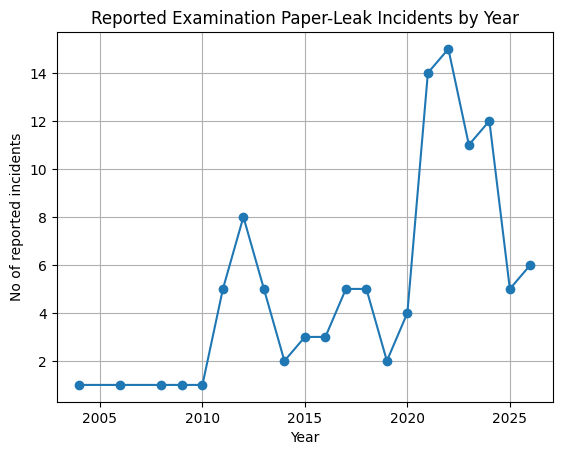

In [6]:
plt.Figure(figsize=(12,6))
plt.plot(yearly_incidents.index,yearly_incidents.values,marker="o")
plt.title('Reported Examination Paper-Leak Incidents by Year')
plt.xlabel('Year')
plt.ylabel('No of reported incidents')
plt.grid(True)
plt.show()

In [7]:
## Is there an overall upward/downward trend? --> Upward trend
## The paper leaking events recorded were loww during the period between 2005 and 2010 but there was substantial increase in the incidents from 2021 ownards, 
#  with the highest recorded
#  incident reported in 2022. 

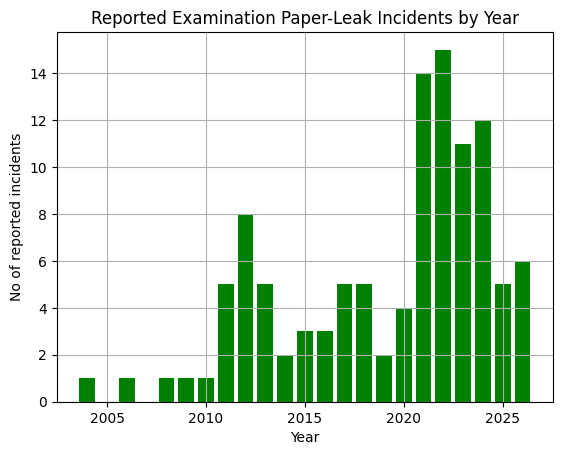

In [8]:
plt.Figure(figsize=(12,6))
plt.bar(yearly_incidents.index,yearly_incidents.values,color='green')
plt.title('Reported Examination Paper-Leak Incidents by Year')
plt.xlabel('Year')
plt.ylabel('No of reported incidents')
plt.grid(True)
plt.show()

### Which examinations are most frequently associated with reported paper-leak incidents?

In [9]:
exam_incidents=df['exam_name'].value_counts()
print(exam_incidents.head(10))

exam_name
Forest Guard recruitment exam                                                                     2
Himachal Pradesh Combined Pre-Medical Test (HP-CPMT) 2006                                         1
Vyapam Patwari Recruitment Examination 2008                                                       1
MP Pre-Medical Test (PMT) 2009                                                                    1
All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004                                                  1
Vyapam Contract Teacher Eligibility Test (Samvida Shala Shikshak Patrata Pariksha Varg-3) 2011    1
CBSE Class 10 & Class 12 Board Examinations 2011                                                  1
AIEEE (All India Engineering Entrance Examination) 2011                                           1
Chhattisgarh Pre-Medical Test (CG-PMT) 2011                                                       1
Uttar Pradesh Teacher Eligibility Test (UPTET) 2011                                       

In [10]:
body_type_incidents =  df['body_type'].value_counts()
print(body_type_incidents)

body_type
State      88
Central    22
Name: count, dtype: int64


In [11]:
## calculate percentage of body_type

body_type_percentage = df['body_type'].value_counts(normalize=True)*100
print(body_type_percentage)

body_type
State      80.0
Central    20.0
Name: proportion, dtype: float64


In [12]:
## State-level examinations accounted for 80% of the reported paper-leak incidents, 
## compared with 20% for central-level examinations, 
## indicating that reported incidents were significantly more concentrated among state-level examinations.

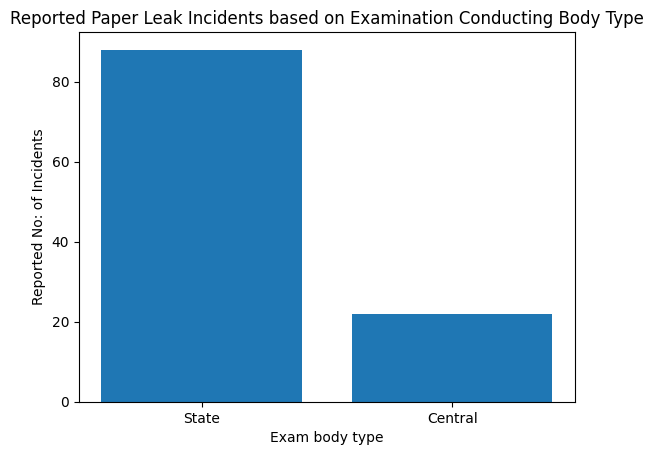

In [13]:
plt.Figure(figsize=(12,12))
plt.bar(body_type_incidents.index,body_type_incidents.values)
plt.title('Reported Paper Leak Incidents based on Examination Conducting Body Type')
plt.xlabel('Exam body type')
plt.ylabel('Reported No: of Incidents')
plt.show()

### Are these state-level incidents concentrated in particular areas/states?

In [14]:
df.head()

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,arrests,convictions,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence,year
0,PL-0001,2004-04-11,UPA (2004-May2014),All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004,Central Board of Secondary Education (CBSE),Central,All India,Confirmed,Exam cancelled + Arrests-FIR + Probe (CBI/SIT),Physics and chemistry papers leaked in New Del...,2.0,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2004/20040412/mai...,High,2004
1,PL-0002,2006-06-01,UPA (2004-May2014),Himachal Pradesh Combined Pre-Medical Test (HP...,Himachal Pradesh University,State,Himachal Pradesh,Confirmed,Retest + Arrests-FIR,HP-CPMT medical entrance paper leaked via a to...,NaN,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2006/20060831/him...,Medium,2006
2,PL-0003,2008-01-01,UPA (2004-May2014),Vyapam Patwari Recruitment Examination 2008,Madhya Pradesh Professional Examination Board ...,State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Accused produced forged educational certificat...,NaN,10.0,NaN,NaN,NaN,The420.in,https://the420.in/vyapam-scam-cbi-court-patwar...,High,2008
3,PL-0004,2009-07-08,UPA (2004-May2014),MP Pre-Medical Test (PMT) 2009,Vyapam (MPPEB),State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Paid solvers/impersonators sat the exam in pla...,NaN,NaN,114.0,NaN,NaN,The Free Press Journal,https://www.freepressjournal.in/education/indo...,High,2009
4,PL-0005,2010-06-06,UPA (2004-May2014),RRB Mumbai 2010 recruitment exam (Assistant Lo...,"Railway Recruitment Board (RRB), Mumbai",Central,All India,Confirmed,Arrests-FIR + Probe (CBI/SIT),CBI registered a case on 15 June 2010 over the...,15.0,10.0,NaN,NaN,NaN,The Week,https://www.theweek.in/wire-updates/national/2...,High,2010


In [15]:
area_incidents= df['area'].value_counts()
print(area_incidents)

area
All India                                             16
Madhya Pradesh                                        13
Uttar Pradesh                                          6
Gujarat                                                5
Maharashtra                                            4
Chhattisgarh                                           3
Uttarakhand (Haridwar)                                 3
Uttar Pradesh (statewide)                              3
Haryana                                                2
Uttarakhand                                            2
Rajasthan                                              2
Assam                                                  2
Delhi (NCT of Delhi)                                   2
Rajasthan (Jodhpur)                                    2
Himachal Pradesh                                       2
Karnataka                                              2
Jharkhand (Ranchi)                                     2
Uttar Pradesh (Lucknow)   

In [16]:
df['area_clean'] = (df['area'].str.replace(r'\s*\(.*?\)','',regex=True).str.strip())
print(df[['area','area_clean']].drop_duplicates().sort_values('area_clean'))

                                                  area  \
0                                            All India   
6                            Andaman & Nicobar Islands   
65                                      Andhra Pradesh   
71                                   Arunachal Pradesh   
18                                               Assam   
66                                Bihar (Ara, Bhojpur)   
73                   Bihar (528 centres, 38 districts)   
90                                   Bihar (statewide)   
97                     Bihar (Patna and other centres)   
98                     Bihar (Bapu Exam Centre, Patna)   
86                                Bihar (37 districts)   
31                  Bihar (Patna) / Jharkhand (arrest)   
8                                         Chhattisgarh   
13                                               Delhi   
24                                Delhi (NCT of Delhi)   
41                                             Gujarat   
33            

In [17]:
df['area_clean'] = df['area'].str.strip()
df.loc[df['area_clean'].str.contains('Bihar',case=False,na=False)]='Bihar'

C:\Users\Amie Elsuba Scaria\AppData\Local\Temp\ipykernel_11828\3346497911.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Bihar' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  df.loc[df['area_clean'].str.contains('Bihar',case=False,na=False)]='Bihar'
C:\Users\Amie Elsuba Scaria\AppData\Local\Temp\ipykernel_11828\3346497911.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Bihar' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  df.loc[df['area_clean'].str.contains('Bihar',case=False,na=False)]='Bihar'
C:\Users\Amie Elsuba Scaria\AppData\Local\Temp\ipykernel_11828\3346497911.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'Bihar' has dtype inc

In [18]:
df['area_clean'].value_counts()

area_clean
All India                                             16
Madhya Pradesh                                        13
Bihar                                                  7
Uttar Pradesh                                          6
Gujarat                                                5
Maharashtra                                            4
Uttar Pradesh (statewide)                              3
Chhattisgarh                                           3
Uttarakhand (Haridwar)                                 3
Himachal Pradesh                                       2
Haryana                                                2
Jharkhand (Ranchi)                                     2
Rajasthan (Jodhpur)                                    2
Karnataka                                              2
Uttarakhand                                            2
Delhi (NCT of Delhi)                                   2
Rajasthan                                              2
Assam               

In [19]:
print(sorted(df['area_clean'].unique()))

['All India', 'Andaman & Nicobar Islands', 'Andhra Pradesh', 'Arunachal Pradesh', 'Assam', 'Bihar', 'Chhattisgarh', 'Delhi', 'Delhi (NCT of Delhi)', 'Gujarat', 'Haryana', 'Haryana (Hisar)', 'Haryana (Jind)', 'Haryana (Kaithal)', 'Himachal Pradesh', 'Himachal Pradesh (Hamirpur)', 'Jammu & Kashmir', 'Jharkhand', 'Jharkhand (Jamtara/Chatra/Dhanbad)', 'Jharkhand (Ranchi)', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Maharashtra (Nagpur)', 'Manipur (Imphal)', 'Odisha', 'Punjab (Bathinda highlighted)', 'Punjab (Faridkot/Kotkapura/Ferozepur)', 'Punjab (Patiala; centres statewide)', 'Punjab (leak traced to Goindwal Sahib, Tarn Taran)', 'Rajasthan', 'Rajasthan (Jaipur)', 'Rajasthan (Jaipur/Dausa)', 'Rajasthan (Jaipur/Jhotwara)', 'Rajasthan (Jaipur/Kota/Ajmer)', 'Rajasthan (Jodhpur)', 'Rajasthan (Rajsamand)', 'Rajasthan (Udaipur)', 'Rajasthan (statewide)', 'Tamil Nadu (Tiruvannamalai)', 'Telangana', 'Uttar Pradesh', 'Uttar Pradesh (Kanpur/Lucknow)', 'Uttar Pradesh (Lucknow)', 'Uttar Pradesh (

In [20]:
print(df['area_clean'].value_counts())

area_clean
All India                                             16
Madhya Pradesh                                        13
Bihar                                                  7
Uttar Pradesh                                          6
Gujarat                                                5
Maharashtra                                            4
Uttar Pradesh (statewide)                              3
Chhattisgarh                                           3
Uttarakhand (Haridwar)                                 3
Himachal Pradesh                                       2
Haryana                                                2
Jharkhand (Ranchi)                                     2
Rajasthan (Jodhpur)                                    2
Karnataka                                              2
Uttarakhand                                            2
Delhi (NCT of Delhi)                                   2
Rajasthan                                              2
Assam               

In [21]:
df['area_clean'] = (df['area'].str.replace(r'\s*\(.*?\)','',regex=True).str.strip())

In [22]:
states=[
    'Andaman & Nicobar Islands',
    'Andhra Pradesh',
    'Arunachal Pradesh',
    'Assam',
    'Bihar',
    'Chhattisgarh',
    'Delhi',
    'Gujarat',
    'Haryana',
    'Himachal Pradesh',
    'Jammu & Kashmir',
    'Jharkhand',
    'Karnataka',
    'Madhya Pradesh',
    'Maharashtra',
    'Manipur',
    'Punjab',
    'Rajasthan',
    'Uttar Pradesh',
    'Uttarakhand',
    'West Bengal'
]

for state in states:
    df.loc[
        df['area_clean'].str.contains(state,case=False,na=False),
        'area_clean'
    ] = state

In [23]:
df['area_clean'].value_counts()

area_clean
All India                    16
Madhya Pradesh               13
Uttar Pradesh                12
Rajasthan                    11
Bihar                         7
Uttarakhand                   6
Haryana                       5
Maharashtra                   5
Gujarat                       5
Punjab                        4
Jharkhand                     4
Chhattisgarh                  3
Himachal Pradesh              3
Delhi                         3
Assam                         2
Karnataka                     2
Andaman & Nicobar Islands     1
Jammu & Kashmir               1
Manipur                       1
West Bengal                   1
Tamil Nadu                    1
Andhra Pradesh                1
Arunachal Pradesh             1
Telangana                     1
Odisha                        1
Name: count, dtype: int64

## Which areas have the highest number of reported paper-leak incidents?

In [24]:
area_incidents= df['area_clean'].value_counts()
print(area_incidents)

area_clean
All India                    16
Madhya Pradesh               13
Uttar Pradesh                12
Rajasthan                    11
Bihar                         7
Uttarakhand                   6
Haryana                       5
Maharashtra                   5
Gujarat                       5
Punjab                        4
Jharkhand                     4
Chhattisgarh                  3
Himachal Pradesh              3
Delhi                         3
Assam                         2
Karnataka                     2
Andaman & Nicobar Islands     1
Jammu & Kashmir               1
Manipur                       1
West Bengal                   1
Tamil Nadu                    1
Andhra Pradesh                1
Arunachal Pradesh             1
Telangana                     1
Odisha                        1
Name: count, dtype: int64


In [25]:
state_incidents =  area_incidents.drop("All India")
print(state_incidents)

area_clean
Madhya Pradesh               13
Uttar Pradesh                12
Rajasthan                    11
Bihar                         7
Uttarakhand                   6
Haryana                       5
Maharashtra                   5
Gujarat                       5
Punjab                        4
Jharkhand                     4
Chhattisgarh                  3
Himachal Pradesh              3
Delhi                         3
Assam                         2
Karnataka                     2
Andaman & Nicobar Islands     1
Jammu & Kashmir               1
Manipur                       1
West Bengal                   1
Tamil Nadu                    1
Andhra Pradesh                1
Arunachal Pradesh             1
Telangana                     1
Odisha                        1
Name: count, dtype: int64


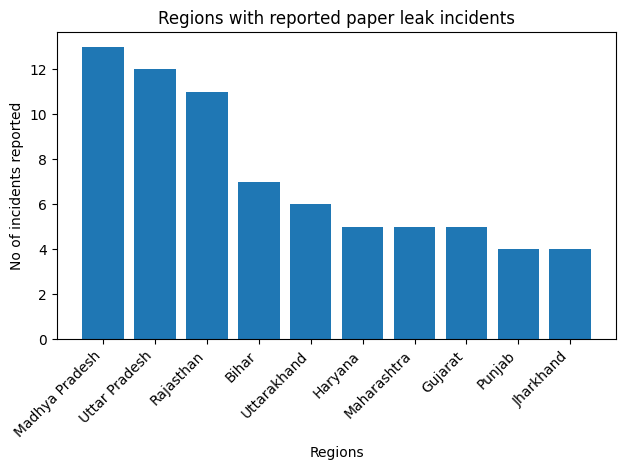

In [26]:
plt.Figure(figsize=(12,6))
plt.bar(state_incidents.head(10).index,state_incidents.head(10).values)
plt.title('Regions with reported paper leak incidents')
plt.xlabel('Regions')
plt.ylabel('No of incidents reported')

plt.xticks(rotation=45, ha='right')         ### rotates the labels so they don't overlap.
plt.tight_layout()                          ### makes sure the labels don't get cut off.


plt.show()

In [27]:
## Madhya Pradesh, Uttar Pradesh and Rajasthan recordedthe highest number of recorded paper leak incidents with figures at 13,12 and 11 respectively.
## The incidents appear to be concentrated in a small number of states, while several other states recorded relatively fewer cases.

In [28]:
df['leak_status'].value_counts()

leak_status
Confirmed    83
Alleged      12
Bihar         7
Denied        5
Suspected     3
Name: count, dtype: int64

In [29]:
df[df['leak_status']=='Bihar']

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,arrests,convictions,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence,year,area_clean
31,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
66,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
73,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
86,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
90,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
97,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
98,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar


In [30]:
df.loc[
    df['leak_status']=='Bihar',
    ['incident_id','date','area','leak_status','exam_name','note']
    ]

,incident_id,date,area,leak_status,exam_name,note
31,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
66,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
73,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
86,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
90,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
97,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar
98,Bihar,Bihar,Bihar,Bihar,Bihar,Bihar


In [31]:
df_analysis= df[df['leak_status']!='Bihar'].copy()
df_analysis.shape

(103, 20)

In [32]:
df.nunique(axis=1).sort_values().head(15)

31     1
90     1
97     1
98     1
86     1
66     1
73     1
1     14
50    14
52    14
10    14
5     14
12    14
11    14
30    14
dtype: int64

In [33]:
leaked_status_counts=df_analysis['leak_status'].value_counts()
print(leaked_status_counts)

leak_status
Confirmed    83
Alleged      12
Denied        5
Suspected     3
Name: count, dtype: int64


In [34]:
leaked_status_percentage=(
    df_analysis['leak_status'].value_counts(normalize=True)*100
)

print(leaked_status_percentage.round(2))

leak_status
Confirmed    80.58
Alleged      11.65
Denied        4.85
Suspected     2.91
Name: proportion, dtype: float64


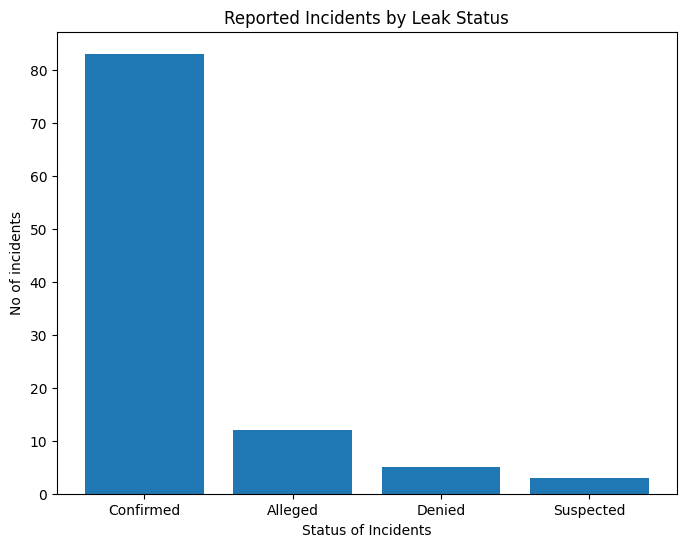

In [35]:
plt.figure(figsize=(8,6))
plt.bar(leaked_status_counts.index,leaked_status_counts.values)
plt.title('Reported Incidents by Leak Status')
plt.xlabel('Status of Incidents')
plt.ylabel('No of incidents')
##plt.xticks(rotation=45,ha='right')
plt.show()

In [36]:
### Confirmed incidents account for 80.58% of the usable records, substantially higher than alleged (11.65%), denied (4.85%), and suspected (2.91%) incidents. 
### This indicates that the majority of incidents recorded in the dataset were classified as confirmed.
### Seven records were excluded from status analysis because the value "Bihar" was repeated across multiple fields, indicating corrupted records.

### How many reported incidents resulted in arrests?

In [37]:
df_analysis['arrests'].describe()

count     58.0
unique    32.0
top        3.0
freq       9.0
Name: arrests, dtype: float64

In [38]:
df_analysis['arrests'].isna().sum()

np.int64(45)

In [39]:
df_analysis['arrests'].dtype

dtype('O')

In [40]:
df_analysis['arrests'].value_counts(dropna=False)

arrests
NaN      45
3.0       9
12.0      4
5.0       4
2.0       3
10.0      3
7.0       2
9.0       2
1.0       2
18.0      2
20.0      2
17.0      2
6.0       2
54.0      2
15.0      1
13.0      1
11.0      1
24.0      1
167.0     1
38.0      1
30.0      1
23.0      1
14.0      1
88.0      1
70.0      1
8.0       1
21.0      1
44.0      1
19.0      1
37.0      1
0.0       1
26.0      1
164.0     1
Name: count, dtype: int64

In [41]:
## Right now arrests column is of datatyoe object. Convert it to numeric

In [42]:
df_analysis['arrests_numeric']=pd.to_numeric(
    df_analysis['arrests'],
    errors='coerce'       ### If Pandas encounters something that cannot be converted into a number, turn it into NaN instead of producing an error.
)

In [43]:
df_analysis['arrests_numeric'].dtype

dtype('float64')

In [44]:
df_analysis['arrests_numeric'].describe()

count     58.000000
mean      20.810345
std       32.600429
min        0.000000
25%        3.500000
50%       10.500000
75%       20.000000
max      167.000000
Name: arrests_numeric, dtype: float64

In [45]:
df_analysis['arrests_numeric'].value_counts(dropna=False)

arrests_numeric
NaN      45
3.0       9
12.0      4
5.0       4
2.0       3
10.0      3
7.0       2
9.0       2
1.0       2
18.0      2
20.0      2
17.0      2
6.0       2
54.0      2
15.0      1
13.0      1
11.0      1
24.0      1
167.0     1
38.0      1
30.0      1
23.0      1
14.0      1
88.0      1
70.0      1
8.0       1
21.0      1
44.0      1
19.0      1
37.0      1
0.0       1
26.0      1
164.0     1
Name: count, dtype: int64

In [46]:
inicidents_with_arrests=(df_analysis['arrests_numeric']>0).sum()
print(inicidents_with_arrests)


57


In [47]:
arrest_data=df_analysis['arrests_numeric'].notna().sum()

In [48]:
arrest_percenatage = (
    inicidents_with_arrests/arrest_data * 100
)

print(round(arrest_percenatage,2))

98.28


In [49]:
total_arrests=df_analysis['arrests_numeric'].sum()
print(total_arrests)

1207.0


In [50]:
df_analysis['arrests'].value_counts(dropna=False).head(20)

arrests
NaN      45
3.0       9
12.0      4
5.0       4
2.0       3
10.0      3
7.0       2
9.0       2
1.0       2
18.0      2
20.0      2
17.0      2
6.0       2
54.0      2
15.0      1
13.0      1
11.0      1
24.0      1
167.0     1
38.0      1
Name: count, dtype: int64

In [51]:
(df_analysis['arrests_numeric'] == 0).value_counts(dropna=False)


arrests_numeric
False    102
True       1
Name: count, dtype: int64

In [52]:
df_analysis['arrests_numeric'] = pd.to_numeric(
    df_analysis['arrests'],
    errors='coerce'
)

In [53]:
df_analysis['arrests_numeric'].value_counts(dropna=False).head(20)

arrests_numeric
NaN      45
3.0       9
12.0      4
5.0       4
2.0       3
10.0      3
7.0       2
9.0       2
1.0       2
18.0      2
20.0      2
17.0      2
6.0       2
54.0      2
15.0      1
13.0      1
11.0      1
24.0      1
167.0     1
38.0      1
Name: count, dtype: int64

In [54]:
incidents_with_no_arrests = (df_analysis['arrests_numeric'] == 0).sum()

print(incidents_with_no_arrests)

1


In [55]:
arrest_status= df_analysis['arrests_numeric'].dropna().apply(
    lambda x: 'Atleast one arrest' if x>0 else 'No arrests'
)

arrest_status_counts= arrest_status.value_counts()
print(arrest_status_counts)

arrests_numeric
Atleast one arrest    57
No arrests             1
Name: count, dtype: int64


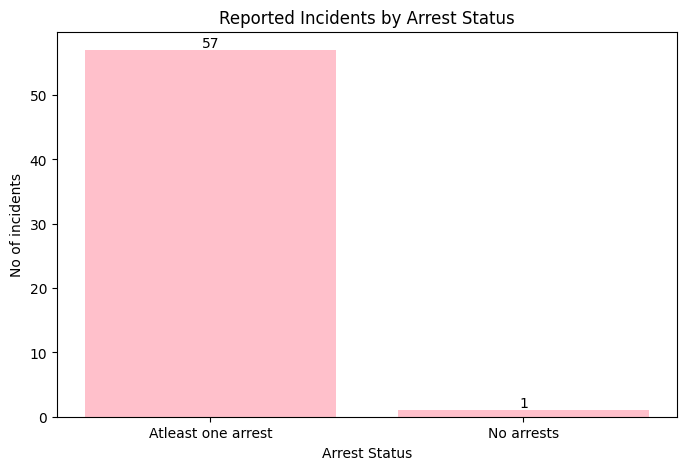

In [56]:
plt.figure(figsize=(8,5))
bars = plt.bar(arrest_status_counts.index,arrest_status_counts.values,color='pink')
plt.title('Reported Incidents by Arrest Status')
plt.xlabel('Arrest Status')
plt.ylabel('No of incidents')
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() /2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.show()

In [57]:
### Among the 58 incidents with available arrest information, 57 (98.28%) recorded at least one arrest, while only one incident recorded zero arrests.
### A total of 1,207 arrests were recorded across these incidents. However, arrest information was missing for 45 of the 103 usable records, 
### so this finding should be interpreted only among incidents with available arrest data.


### Which reported incidents had the highest number of arrests?

In [58]:
df_analysis.head(5)

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,...,convictions,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence,year,area_clean,arrests_numeric
0,PL-0001,2004-04-11 00:00:00,UPA (2004-May2014),All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004,Central Board of Secondary Education (CBSE),Central,All India,Confirmed,Exam cancelled + Arrests-FIR + Probe (CBI/SIT),Physics and chemistry papers leaked in New Del...,...,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2004/20040412/mai...,High,2004,All India,2.0
1,PL-0002,2006-06-01 00:00:00,UPA (2004-May2014),Himachal Pradesh Combined Pre-Medical Test (HP...,Himachal Pradesh University,State,Himachal Pradesh,Confirmed,Retest + Arrests-FIR,HP-CPMT medical entrance paper leaked via a to...,...,NaN,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2006/20060831/him...,Medium,2006,Himachal Pradesh,NaN
2,PL-0003,2008-01-01 00:00:00,UPA (2004-May2014),Vyapam Patwari Recruitment Examination 2008,Madhya Pradesh Professional Examination Board ...,State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Accused produced forged educational certificat...,...,10.0,NaN,NaN,NaN,The420.in,https://the420.in/vyapam-scam-cbi-court-patwar...,High,2008,Madhya Pradesh,NaN
3,PL-0004,2009-07-08 00:00:00,UPA (2004-May2014),MP Pre-Medical Test (PMT) 2009,Vyapam (MPPEB),State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Paid solvers/impersonators sat the exam in pla...,...,NaN,114.0,NaN,NaN,The Free Press Journal,https://www.freepressjournal.in/education/indo...,High,2009,Madhya Pradesh,NaN
4,PL-0005,2010-06-06 00:00:00,UPA (2004-May2014),RRB Mumbai 2010 recruitment exam (Assistant Lo...,"Railway Recruitment Board (RRB), Mumbai",Central,All India,Confirmed,Arrests-FIR + Probe (CBI/SIT),CBI registered a case on 15 June 2010 over the...,...,10.0,NaN,NaN,NaN,The Week,https://www.theweek.in/wire-updates/national/2...,High,2010,All India,15.0


In [59]:
top_arrest_incidents=df_analysis[
    ['incident_id','date','area_clean','exam_name','arrests_numeric']
].sort_values(                                                                  ## sorting a DataFrame by a numeric column
    'arrests_numeric',
    ascending=False
)

top_arrest_incidents.head(10)

,incident_id,date,area_clean,exam_name,arrests_numeric
51,PL-0052,2021-08-07 00:00:00,Haryana,HSSC Police Constable (Male) recruitment exam,167.0
106,PL-0107,2026-04-12 00:00:00,Jharkhand,Jharkhand Excise Constable Competitive Exam (J...,164.0
64,PL-0065,2022-03-27 00:00:00,Himachal Pradesh,Himachal Pradesh Police Constable Recruitment ...,88.0
65,PL-0066,2022-04-27 00:00:00,Andhra Pradesh,SSC (Class 10) board examination,70.0
89,PL-0090,2024-02-17 00:00:00,Uttar Pradesh,UP Police Constable Recruitment Exam 2024,54.0
53,PL-0054,2021-09-13 00:00:00,Rajasthan,Sub-Inspector (SI) recruitment exam 2021,54.0
74,PL-0075,2022-12-24 00:00:00,Rajasthan,Senior Teacher Grade II (2nd Grade Teacher) Ge...,44.0
54,PL-0055,2021-09-26 00:00:00,Rajasthan,REET 2021 (Rajasthan Eligibility Exam for Teac...,38.0
78,PL-0079,2023-02-25 00:00:00,Rajasthan,REET 2023 (teacher eligibility test),37.0
55,PL-0056,2021-10-03 00:00:00,Karnataka,Police Sub-Inspector (PSI) recruitment exam,30.0


In [60]:
## The HSSC Police Constable recruitment examination conducted in Haryana recorded the highest number of arrests, with 167 arrests. 
## This was closely followed by the Jharkhand Excise Constable Competitive Examination, which recorded 164 arrests. 
## Among the top 10 incidents with the highest recorded arrests, Rajasthan accounted for four incidents.

### Which regions have the highest total number of recorded arrests?

In [61]:
arrests_by_region = (
    df_analysis.groupby('area_clean')['arrests_numeric'].sum()
    .sort_values(ascending=False)
)

print(arrests_by_region.head(10))

area_clean
Rajasthan           222.0
Haryana             190.0
Jharkhand           174.0
Uttar Pradesh       154.0
Himachal Pradesh     94.0
Andhra Pradesh       70.0
Uttarakhand          47.0
Karnataka            40.0
All India            37.0
Maharashtra          35.0
Name: arrests_numeric, dtype: float64


In [62]:
### Rajasthan recorded the highest total number of arrests across reported paper-leak incidents, with 222 arrests, followed by Haryana with 190 and Jharkhand with 174.

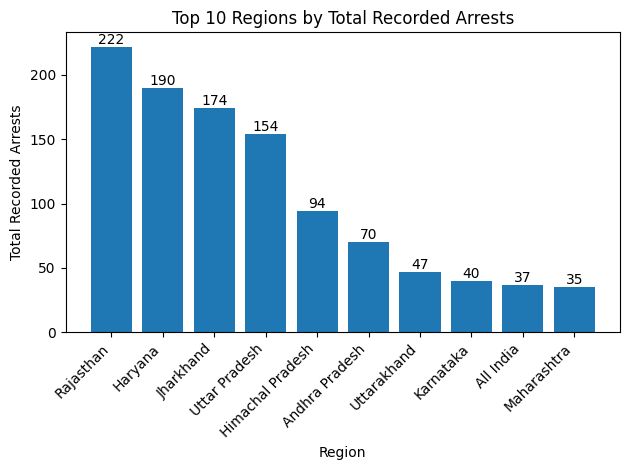

In [63]:
plt.Figure(figsize=(8,5))
top_regions = arrests_by_region.head(10)
bars = plt.bar(top_regions.index,top_regions.values)
plt.title('Top 10 Regions by Total Recorded Arrests')
plt.xlabel('Region')
plt.ylabel('Total Recorded Arrests')
plt.xticks(rotation=45,ha='right')
plt.tight_layout()
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.show()

### Do certain exam types have more arrests?

In [64]:
arrests_by_exam=(
    df_analysis.groupby('exam_name')['arrests_numeric'].sum()
    .sort_values(ascending=False)
)

print(arrests_by_exam)

exam_name
HSSC Police Constable (Male) recruitment exam                                                     167.0
Jharkhand Excise Constable Competitive Exam (JECCE)                                               164.0
Himachal Pradesh Police Constable Recruitment Written Test 2022 (1,334 posts)                      88.0
SSC (Class 10) board examination                                                                   70.0
UP Police Constable Recruitment Exam 2024                                                          54.0
                                                                                                  ...  
UP Police Inspector (Sub-Inspector/Inspector) Online Recruitment Test 2017                          0.0
Vyapam Contract Teacher Eligibility Test (Samvida Shala Shikshak Patrata Pariksha Varg-3) 2011      0.0
Vyapam Patwari Recruitment Examination 2008                                                         0.0
Vyapam Police Constable Recruitment Examination 2012  

In [65]:
df_analysis['exam_category']='Other'

In [66]:
df_analysis['exam_name'].str.contains(
    'police|constable|recruitment',
    case=False,
    na=False
).sum()

np.int64(47)

In [67]:
df_analysis.loc[
    df_analysis['exam_name'].str.contains(
        'police|constable|recruitment',
        case=False,
        na=False
    ),'exam_category'
] = 'police/recruitment'

In [68]:
df_analysis.head(5)

,incident_id,date,era,exam_name,conducting_body,body_type,area,leak_status,action_taken,note,...,aspirants_affected,linked_deaths,deaths_note,source_name,source_url,confidence,year,area_clean,arrests_numeric,exam_category
0,PL-0001,2004-04-11 00:00:00,UPA (2004-May2014),All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004,Central Board of Secondary Education (CBSE),Central,All India,Confirmed,Exam cancelled + Arrests-FIR + Probe (CBI/SIT),Physics and chemistry papers leaked in New Del...,...,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2004/20040412/mai...,High,2004,All India,2.0,Other
1,PL-0002,2006-06-01 00:00:00,UPA (2004-May2014),Himachal Pradesh Combined Pre-Medical Test (HP...,Himachal Pradesh University,State,Himachal Pradesh,Confirmed,Retest + Arrests-FIR,HP-CPMT medical entrance paper leaked via a to...,...,NaN,NaN,NaN,The Tribune,https://www.tribuneindia.com/2006/20060831/him...,Medium,2006,Himachal Pradesh,NaN,Other
2,PL-0003,2008-01-01 00:00:00,UPA (2004-May2014),Vyapam Patwari Recruitment Examination 2008,Madhya Pradesh Professional Examination Board ...,State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Accused produced forged educational certificat...,...,NaN,NaN,NaN,The420.in,https://the420.in/vyapam-scam-cbi-court-patwar...,High,2008,Madhya Pradesh,NaN,police/recruitment
3,PL-0004,2009-07-08 00:00:00,UPA (2004-May2014),MP Pre-Medical Test (PMT) 2009,Vyapam (MPPEB),State,Madhya Pradesh,Confirmed,Arrests-FIR + Probe (CBI/SIT),Paid solvers/impersonators sat the exam in pla...,...,114.0,NaN,NaN,The Free Press Journal,https://www.freepressjournal.in/education/indo...,High,2009,Madhya Pradesh,NaN,Other
4,PL-0005,2010-06-06 00:00:00,UPA (2004-May2014),RRB Mumbai 2010 recruitment exam (Assistant Lo...,"Railway Recruitment Board (RRB), Mumbai",Central,All India,Confirmed,Arrests-FIR + Probe (CBI/SIT),CBI registered a case on 15 June 2010 over the...,...,NaN,NaN,NaN,The Week,https://www.theweek.in/wire-updates/national/2...,High,2010,All India,15.0,police/recruitment


In [69]:
df_analysis['exam_name'].str.contains(
        'medical|pre-medical|entrance|neet|aiims',
        case=False,
        na=False
    ).sum()


np.int64(20)

In [70]:
medical_matches=df_analysis[
    df_analysis['exam_name'].str.contains(
        'medical|pre-medical|entrance|neet|aiims',
        case=False,
        na=False
    )
]

print(medical_matches['exam_name'])

0       All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004
1      Himachal Pradesh Combined Pre-Medical Test (HP...
3                         MP Pre-Medical Test (PMT) 2009
7      AIEEE (All India Engineering Entrance Examinat...
8            Chhattisgarh Pre-Medical Test (CG-PMT) 2011
11           MP Pre-PG (Post-Graduate Medical) Test 2012
13     AIIMS Post-Graduate (MD/MS) Entrance Examinati...
15     Jammu & Kashmir Common Entrance Test (JKCET) 2...
16                        MP Pre-Medical Test (PMT) 2012
21                        MP Pre-Medical Test (PMT) 2013
26               AIPMT 2015 (All India Pre-Medical Test)
30                               NEET-UG 2016 (Phase II)
32                                          NEET-UG 2017
45             Medical Officer (Dental) recruitment test
49     Army Soldier General Duty Common Entrance Exam...
52                                          NEET-UG 2021
83          AIIMS NORCET-4 (Nursing Officer Recruitment)
92                             

In [71]:
medical_condition=df_analysis[
    df_analysis['exam_name'].str.contains(
        'pre-medical|neet|aipmt|aiims.*entrance|medical entrance',
        case=False,
        na=False
    )
]

In [72]:
type(medical_condition)

pandas.core.frame.DataFrame

In [73]:
medical_condition.shape

(14, 22)

In [74]:
medical_condition = df_analysis['exam_name'].str.contains(
    'pre-medical|neet|aipmt|aiims.*entrance|medical entrance',
    case=False,
    na=False
)

In [75]:
type(medical_condition)

pandas.core.series.Series

In [76]:
medical_condition.shape

(103,)

In [77]:
print(df_analysis.loc[medical_condition, 'exam_name'])

0       All India Pre-Medical Test (AIPMT/CBSE-PMT) 2004
1      Himachal Pradesh Combined Pre-Medical Test (HP...
3                         MP Pre-Medical Test (PMT) 2009
8            Chhattisgarh Pre-Medical Test (CG-PMT) 2011
13     AIIMS Post-Graduate (MD/MS) Entrance Examinati...
16                        MP Pre-Medical Test (PMT) 2012
21                        MP Pre-Medical Test (PMT) 2013
26               AIPMT 2015 (All India Pre-Medical Test)
30                               NEET-UG 2016 (Phase II)
32                                          NEET-UG 2017
52                                          NEET-UG 2021
92                                          NEET-UG 2024
95                                          NEET-PG 2024
107                                         NEET-UG 2026
Name: exam_name, dtype: object


In [78]:
df_analysis.loc[medical_condition,'exam_category']='Medical/Entrance'

In [79]:
df_analysis['exam_category'].value_counts()


exam_category
police/recruitment    47
Other                 42
Medical/Entrance      14
Name: count, dtype: int64

In [80]:
df_analysis.loc[
    df_analysis['exam_category']=='Other',
    'exam_name'
]

5      Vyapam Contract Teacher Eligibility Test (Samv...
6       CBSE Class 10 & Class 12 Board Examinations 2011
7      AIEEE (All India Engineering Entrance Examinat...
9      Uttar Pradesh Teacher Eligibility Test (UPTET)...
10                 MP Food Inspector Selection Test 2012
11           MP Pre-PG (Post-Graduate Medical) Test 2012
14     Karnataka Second PU (Class 12) Board Examinati...
15     Jammu & Kashmir Common Entrance Test (JKCET) 2...
20     SSC Combined Graduate Level (CGL) Examination ...
22     RAS (Rajasthan Administrative Service) Prelimi...
23          CBSE Class 12 Physics Board Examination 2014
25                    UPPCS Preliminary Examination 2015
27       HTET Level-3 (Haryana Teacher Eligibility Test)
33     HCS (Judicial Branch) Preliminary Examination ...
36                                  SSC CGL 2017 Tier-II
37               CBSE Class 12 Economics board exam 2018
38             CBSE Class 10 Mathematics board exam 2018
43                   Teacher El

In [81]:
teacher_condition = df_analysis['exam_name'].str.contains(
    'teacher|eligibility|TET|REET|HTET',
    case=False,
    na=False
)

print(df_analysis.loc[teacher_condition, 'exam_name'])

5      Vyapam Contract Teacher Eligibility Test (Samv...
9      Uttar Pradesh Teacher Eligibility Test (UPTET)...
27       HTET Level-3 (Haryana Teacher Eligibility Test)
28     State Level Selection Test (SLST) 2016 teacher...
35     DSSSB Primary Teacher (PRT) Recruitment Exam f...
43                   Teacher Eligibility Test (TET) 2020
54     REET 2021 (Rajasthan Eligibility Exam for Teac...
57     Uttar Pradesh Teacher Eligibility Test (UPTET)...
74     Senior Teacher Grade II (2nd Grade Teacher) Ge...
78                  REET 2023 (teacher eligibility test)
102                       Teacher Eligibility Test (TET)
108    HTET Level-3 / PGT (Haryana Teacher Eligibilit...
Name: exam_name, dtype: object


In [82]:
df_analysis.loc[
    teacher_condition,
    'exam_category'
] = 'Teacher/Eligibility'

In [83]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment     45
Other                  32
Medical/Entrance       14
Teacher/Eligibility    12
Name: count, dtype: int64

In [84]:
df_analysis.loc[
    df_analysis['exam_category'] == 'Other',
    'exam_name'
]

6       CBSE Class 10 & Class 12 Board Examinations 2011
7      AIEEE (All India Engineering Entrance Examinat...
10                 MP Food Inspector Selection Test 2012
11           MP Pre-PG (Post-Graduate Medical) Test 2012
14     Karnataka Second PU (Class 12) Board Examinati...
15     Jammu & Kashmir Common Entrance Test (JKCET) 2...
20     SSC Combined Graduate Level (CGL) Examination ...
22     RAS (Rajasthan Administrative Service) Prelimi...
23          CBSE Class 12 Physics Board Examination 2014
25                    UPPCS Preliminary Examination 2015
33     HCS (Judicial Branch) Preliminary Examination ...
36                                  SSC CGL 2017 Tier-II
37               CBSE Class 12 Economics board exam 2018
38             CBSE Class 10 Mathematics board exam 2018
44           Sub-Inspector (unarmed branch) written exam
47     Railway GDCE 2021 (General Departmental Compet...
48           HSSC Gram Sachiv (Panchayat Secretary) exam
49     Army Soldier General Dut

In [85]:
board_condition = df_analysis['exam_name'].str.contains(
    'board|class 10|class 12|12th|10th',
    case=False,
    na=False
)

In [86]:
print(df_analysis.loc[board_condition, 'exam_name'])

6       CBSE Class 10 & Class 12 Board Examinations 2011
14     Karnataka Second PU (Class 12) Board Examinati...
23          CBSE Class 12 Physics Board Examination 2014
37               CBSE Class 12 Economics board exam 2018
38             CBSE Class 10 Mathematics board exam 2018
61      Class 10 Science & Class 12 Maths revision exams
65                      SSC (Class 10) board examination
104                 Class 12 Chemistry board examination
105          CGBSE Class 12 Hindi Board Examination 2026
Name: exam_name, dtype: object


In [87]:
df_analysis.loc[
    board_condition,
    'exam_category'
] = 'Board Examination'

In [88]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment     45
Other                  23
Medical/Entrance       14
Teacher/Eligibility    12
Board Examination       9
Name: count, dtype: int64

In [89]:
gov_condition = df_analysis['exam_name'].str.contains(
    'SSC|RAS|UPPCS|UPPSC|HCS|JSSC|Railway|Railways',
    case=False,
    na=False
)

print(df_analysis.loc[gov_condition, 'exam_name'])

20     SSC Combined Graduate Level (CGL) Examination ...
22     RAS (Rajasthan Administrative Service) Prelimi...
25                    UPPCS Preliminary Examination 2015
33     HCS (Judicial Branch) Preliminary Examination ...
36                                  SSC CGL 2017 Tier-II
40     UPSSSC Tubewell Operator (Nalkoop Chalak) Recr...
47     Railway GDCE 2021 (General Departmental Compet...
48           HSSC Gram Sachiv (Panchayat Secretary) exam
51         HSSC Police Constable (Male) recruitment exam
65                      SSC (Class 10) board examination
70          UPSSSC Lekhpal (Mains) Recruitment Exam 2022
87          JSSC CGL (Combined Graduate Level / JGGLCCE)
88     UPPSC Review Officer/Assistant Review Officer ...
96                JSSC CGL / JGGLCCE (re-conducted exam)
99     East Central Railway departmental promotion ex...
100     UPESSC Assistant Professor Recruitment Exam 2025
Name: exam_name, dtype: object


In [90]:
gov_condition = (
    (df_analysis['exam_category'] == 'Other') &
    (df_analysis['exam_name'].str.contains(
        'SSC|RAS|UPPCS|UPPSC|HCS|JSSC|Railway|Railways',
        case=False,
        na=False
    ))
)

In [91]:
print(df_analysis.loc[gov_condition, 'exam_name'])

20    SSC Combined Graduate Level (CGL) Examination ...
22    RAS (Rajasthan Administrative Service) Prelimi...
25                   UPPCS Preliminary Examination 2015
33    HCS (Judicial Branch) Preliminary Examination ...
36                                 SSC CGL 2017 Tier-II
47    Railway GDCE 2021 (General Departmental Compet...
48          HSSC Gram Sachiv (Panchayat Secretary) exam
87         JSSC CGL (Combined Graduate Level / JGGLCCE)
88    UPPSC Review Officer/Assistant Review Officer ...
96               JSSC CGL / JGGLCCE (re-conducted exam)
99    East Central Railway departmental promotion ex...
Name: exam_name, dtype: object


In [92]:
print(df_analysis.loc[gov_condition, 'exam_name'])

20    SSC Combined Graduate Level (CGL) Examination ...
22    RAS (Rajasthan Administrative Service) Prelimi...
25                   UPPCS Preliminary Examination 2015
33    HCS (Judicial Branch) Preliminary Examination ...
36                                 SSC CGL 2017 Tier-II
47    Railway GDCE 2021 (General Departmental Compet...
48          HSSC Gram Sachiv (Panchayat Secretary) exam
87         JSSC CGL (Combined Graduate Level / JGGLCCE)
88    UPPSC Review Officer/Assistant Review Officer ...
96               JSSC CGL / JGGLCCE (re-conducted exam)
99    East Central Railway departmental promotion ex...
Name: exam_name, dtype: object


In [93]:
df_analysis.loc[
    gov_condition,
    'exam_category'
] = 'Government/Competitive'

In [94]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment        45
Medical/Entrance          14
Teacher/Eligibility       12
Other                     12
Government/Competitive    11
Board Examination          9
Name: count, dtype: int64

In [95]:
df_analysis.loc[
    df_analysis['exam_category'] == 'Other',
    'exam_name'
]

7     AIEEE (All India Engineering Entrance Examinat...
10                MP Food Inspector Selection Test 2012
11          MP Pre-PG (Post-Graduate Medical) Test 2012
15    Jammu & Kashmir Common Entrance Test (JKCET) 2...
44          Sub-Inspector (unarmed branch) written exam
49    Army Soldier General Duty Common Entrance Exam...
50    Forest Guard, Secretariat Security Guard and a...
71                      Assistant Engineer (Civil) exam
84    Junior Engineer (Civil) main written exam (Com...
91    JPSC Combined Civil Services Preliminary Exam ...
93                                    UGC-NET June 2024
94    MPPSC State Service & State Forest Service Pre...
Name: exam_name, dtype: object

In [96]:
engineering_condition = (
    (df_analysis['exam_category']=='Other') &
    (df_analysis['exam_name'].str.contains(
        'AIEEE|engineering entrance|JKCET',
        case=False,
        na=False
    ))
)
print(df_analysis.loc[engineering_condition,'exam_name'])

7     AIEEE (All India Engineering Entrance Examinat...
15    Jammu & Kashmir Common Entrance Test (JKCET) 2...
Name: exam_name, dtype: object


In [97]:
df_analysis.loc[engineering_condition,'exam_category']='Engineer/Entrance'

In [98]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment        45
Medical/Entrance          14
Teacher/Eligibility       12
Government/Competitive    11
Other                     10
Board Examination          9
Engineer/Entrance          2
Name: count, dtype: int64

In [99]:
medical_condition = (
    (df_analysis['exam_category']=='Other')&
    (df_analysis['exam_name'].str.contains(
        'pre-medical|pre-pg|neet|aipmt|aiims.*entrance|medical entrance',
        case=False,
        na=False
    ))
)

print(df_analysis.loc[medical_condition,'exam_category'])

11    Other
Name: exam_category, dtype: object


In [100]:
df_analysis.loc[medical_condition,'exam_category']= "Medical/Entrance"

In [101]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment        45
Medical/Entrance          15
Teacher/Eligibility       12
Government/Competitive    11
Board Examination          9
Other                      9
Engineer/Entrance          2
Name: count, dtype: int64

In [102]:
police_condition = (
    (df_analysis['exam_category']=='Other')&
    (df_analysis['exam_name'].str.contains(
        'sub-inspector|police',
        case=False,
        na=False
    ))
)

print(df_analysis.loc[police_condition,'exam_category'])

44    Other
Name: exam_category, dtype: object


In [103]:
df_analysis.loc[police_condition,'exam_category']='police/recruitment'

In [104]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment        46
Medical/Entrance          15
Teacher/Eligibility       12
Government/Competitive    11
Board Examination          9
Other                      8
Engineer/Entrance          2
Name: count, dtype: int64

In [105]:
df_analysis.loc[
    df_analysis['exam_category'] == 'Other',
    'exam_name'
]

10                MP Food Inspector Selection Test 2012
49    Army Soldier General Duty Common Entrance Exam...
50    Forest Guard, Secretariat Security Guard and a...
71                      Assistant Engineer (Civil) exam
84    Junior Engineer (Civil) main written exam (Com...
91    JPSC Combined Civil Services Preliminary Exam ...
93                                    UGC-NET June 2024
94    MPPSC State Service & State Forest Service Pre...
Name: exam_name, dtype: object

In [106]:
academic_condition = (
    (df_analysis['exam_category'] == 'Other') &
    (df_analysis['exam_name'].str.contains(
        'UGC-NET',
        case=False,
        na=False
    ))
)

print(df_analysis.loc[academic_condition, 'exam_name'])

93    UGC-NET June 2024
Name: exam_name, dtype: object


In [107]:
df_analysis.loc[
    academic_condition,
    'exam_category'
] = 'Academic/Eligibility'

In [108]:
df_analysis.loc[
    df_analysis['exam_category'] == 'Other',
    'exam_name'
]

10                MP Food Inspector Selection Test 2012
49    Army Soldier General Duty Common Entrance Exam...
50    Forest Guard, Secretariat Security Guard and a...
71                      Assistant Engineer (Civil) exam
84    Junior Engineer (Civil) main written exam (Com...
91    JPSC Combined Civil Services Preliminary Exam ...
94    MPPSC State Service & State Forest Service Pre...
Name: exam_name, dtype: object

In [109]:
gov_other_condition = (
    (df_analysis['exam_category'] == 'Other') &
    (df_analysis['exam_name'].str.contains(
        'Food Inspector|Army|Forest Guard|Secretariat Security|Assistant Engineer|Junior Engineer|JPSC|MPPSC',
        case=False,
        na=False
    ))
)

print(df_analysis.loc[gov_other_condition, 'exam_name'])

10                MP Food Inspector Selection Test 2012
49    Army Soldier General Duty Common Entrance Exam...
50    Forest Guard, Secretariat Security Guard and a...
71                      Assistant Engineer (Civil) exam
84    Junior Engineer (Civil) main written exam (Com...
91    JPSC Combined Civil Services Preliminary Exam ...
94    MPPSC State Service & State Forest Service Pre...
Name: exam_name, dtype: object


In [110]:
df_analysis.loc[
    gov_other_condition,
    'exam_category'
] = 'Government/Competitive'

In [111]:
df_analysis.loc[
    df_analysis['exam_category'] == 'Other',
    'exam_name'
]

Series([], Name: exam_name, dtype: object)

In [112]:
df_analysis['exam_category'].value_counts()

exam_category
police/recruitment        46
Government/Competitive    18
Medical/Entrance          15
Teacher/Eligibility       12
Board Examination          9
Engineer/Entrance          2
Academic/Eligibility       1
Name: count, dtype: int64

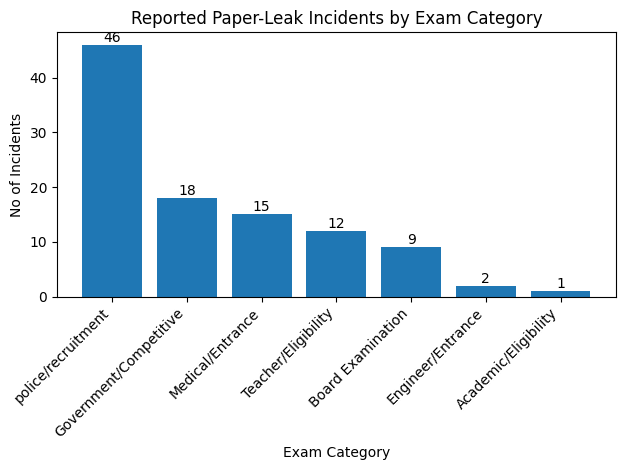

In [113]:
category_counts=df_analysis['exam_category'].value_counts()

plt.Figure(figsize=(8,5))
bars = plt.bar(
    category_counts.index,
    category_counts.values
)

plt.title('Reported Paper-Leak Incidents by Exam Category')
plt.xlabel('Exam Category')
plt.ylabel('No of Incidents')
plt.xticks(rotation=45,ha='right')
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

In [114]:
### Police and recruitment examinations accounted for the largest share of reported paper-leak incidents in the dataset, with 46 of 103 analyzed incidents (~44.7%). 
### Government/competitive and medical/entrance examinations followed with 18 and 15 incidents respectively.

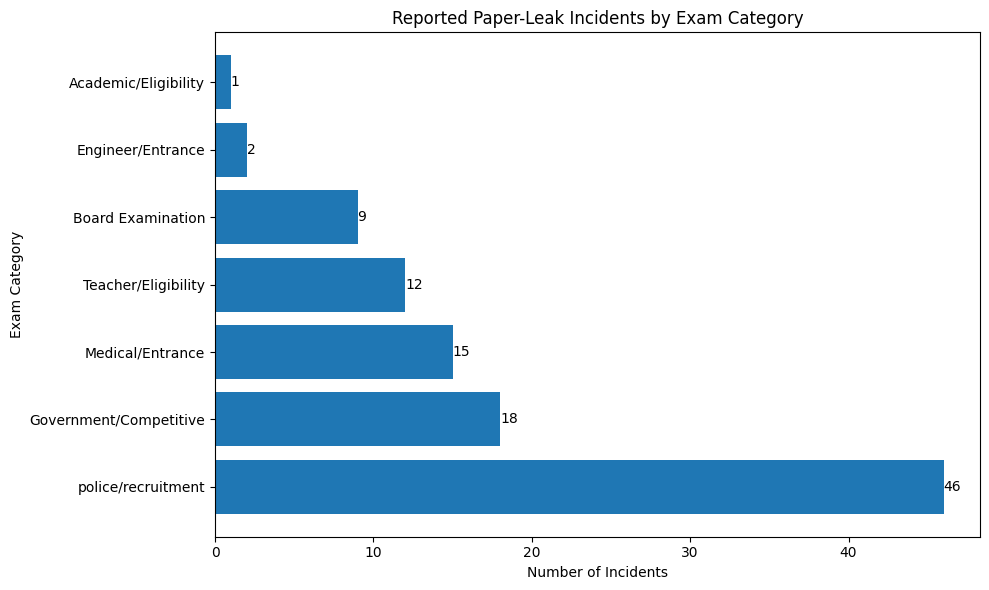

In [115]:
plt.figure(figsize=(10, 6))

bars = plt.barh(
    category_counts.index,
    category_counts.values
)

plt.title('Reported Paper-Leak Incidents by Exam Category')
plt.xlabel('Number of Incidents')
plt.ylabel('Exam Category')

for bar in bars:
    plt.text(
        bar.get_width(),
        bar.get_y() + bar.get_height() / 2,
        int(bar.get_width()),
        va='center'
    )

plt.tight_layout()
plt.show()

### Which exam categories have the highest total number of recorded arrests?

In [116]:
arrests_by_category= (
    df_analysis.groupby('exam_category')['arrests_numeric']
    .sum()
    .sort_values(ascending=False)
)

print(arrests_by_category)

exam_category
police/recruitment        789.0
Teacher/Eligibility       190.0
Government/Competitive     99.0
Board Examination          87.0
Medical/Entrance           41.0
Engineer/Entrance           1.0
Academic/Eligibility        0.0
Name: arrests_numeric, dtype: float64


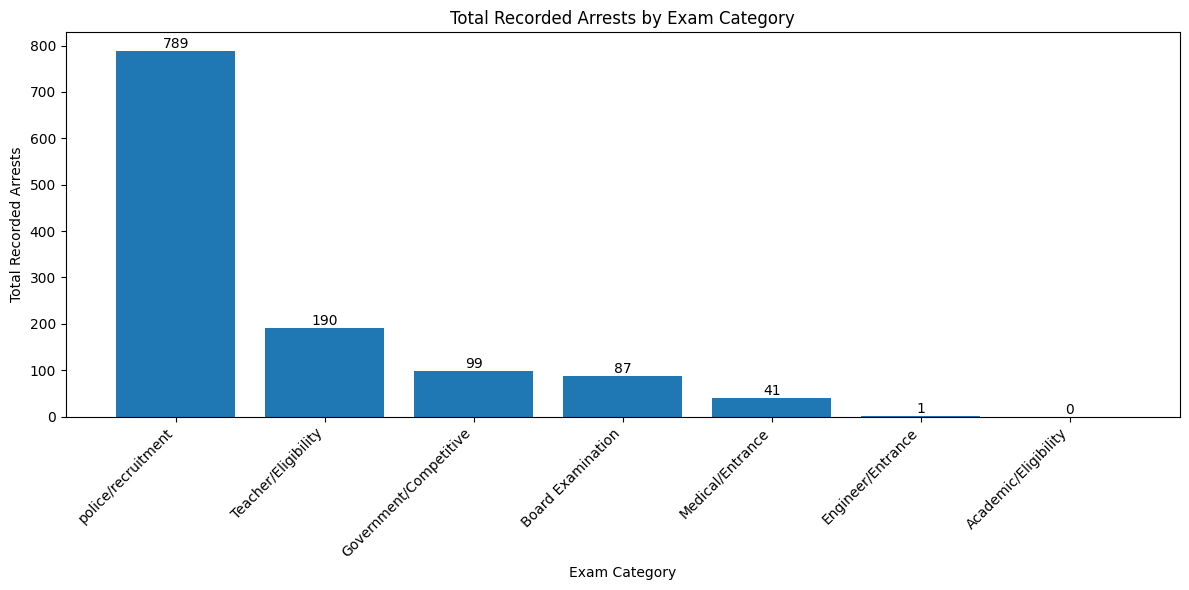

In [117]:
plt.figure(figsize=(12,6))
bars = plt.bar(
    arrests_by_category.index,
    arrests_by_category.values
)

plt.title('Total Recorded Arrests by Exam Category')
plt.ylabel('Total Recorded Arrests')
plt.xlabel('Exam Category')
plt.xticks(rotation=45,ha='right')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

In [118]:
### Police/Recruitment examinations recorded the highest total number of arrests, with 789 arrests across the analyzed incidents. 
### Teacher/Eligibility examinations followed with 190, while Government/Competitive and Board Examination categories recorded 99 and 87 arrests respectively. 
### Medical/Entrance examinations accounted for 41 arrests, while Engineering/Entrance and Academic/Eligibility recorded 1 and 0 arrests.

### How many reported incidents resulted in convictions?

In [119]:
df_analysis['convictions'].dtype

dtype('O')

In [120]:
df_analysis['convictions'].value_counts(dropna=False)

convictions
NaN     93
10.0     2
11.0     2
0.0      2
4.0      1
34.0     1
31.0     1
3.0      1
Name: count, dtype: int64

In [121]:
df_analysis['convictions_numeric'] = pd.to_numeric(
    df_analysis['convictions'],
    errors='coerce'
)

In [122]:
df_analysis['convictions_numeric'].value_counts(dropna=False)

convictions_numeric
NaN     93
10.0     2
11.0     2
0.0      2
4.0      1
34.0     1
31.0     1
3.0      1
Name: count, dtype: int64

In [123]:
incidents_with_convictions =(
    df_analysis['convictions_numeric']>0
).sum()

print(incidents_with_convictions)           ## 8 records with at least one conviction

8


In [124]:
conviction_data = df_analysis['convictions_numeric'].notna().sum()

print(conviction_data)              ## 10  records where conviction information exists

10


In [125]:
conviction_percentage = (
    incidents_with_convictions / len(df_analysis) * 100
)

print(round(conviction_percentage, 2))

7.77


In [126]:
### Among the 103 analyzed incidents, 8 (7.77%) had a recorded conviction count greater than zero, while conviction information was unavailable for 93 incidents.

In [127]:
total_convictions = df_analysis['convictions_numeric'].sum()
print(total_convictions)

114.0


In [128]:
convictions_by_category = (
    df_analysis.groupby('exam_category')['convictions_numeric'].sum().sort_values(ascending=False)
)

print(convictions_by_category)

exam_category
police/recruitment        96.0
Engineer/Entrance         11.0
Board Examination          4.0
Government/Competitive     3.0
Academic/Eligibility       0.0
Medical/Entrance           0.0
Teacher/Eligibility        0.0
Name: convictions_numeric, dtype: float64


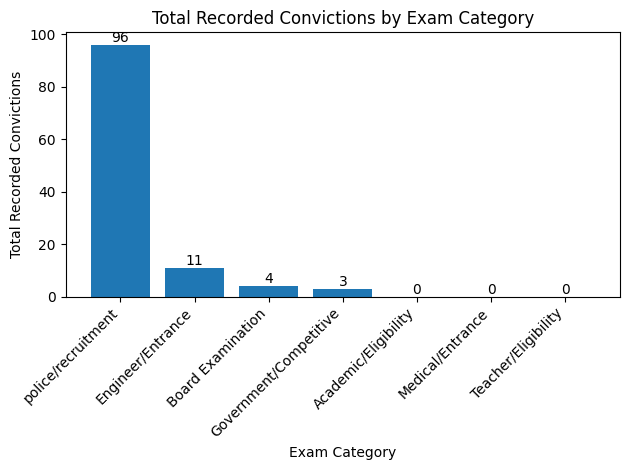

In [129]:
plt.Figure(figsize=(8,8))
bars = plt.bar(
    convictions_by_category.index,
    convictions_by_category.values
)
plt.title('Total Recorded Convictions by Exam Category')
plt.ylabel('Total Recorded Convictions')
plt.xlabel('Exam Category')
plt.xticks(rotation=45, ha='right')

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() /2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

### How do recorded arrests and convictions compare across exam categories?

In [130]:
arrests_convictions_by_category = (
    df_analysis.groupby('exam_category')[
        ['arrests_numeric','convictions_numeric']
    ]
    .sum()
    .sort_values('arrests_numeric',ascending=False)
)

print(arrests_convictions_by_category)

                        arrests_numeric  convictions_numeric
exam_category                                               
police/recruitment                789.0                 96.0
Teacher/Eligibility               190.0                  0.0
Government/Competitive             99.0                  3.0
Board Examination                  87.0                  4.0
Medical/Entrance                   41.0                  0.0
Engineer/Entrance                   1.0                 11.0
Academic/Eligibility                0.0                  0.0


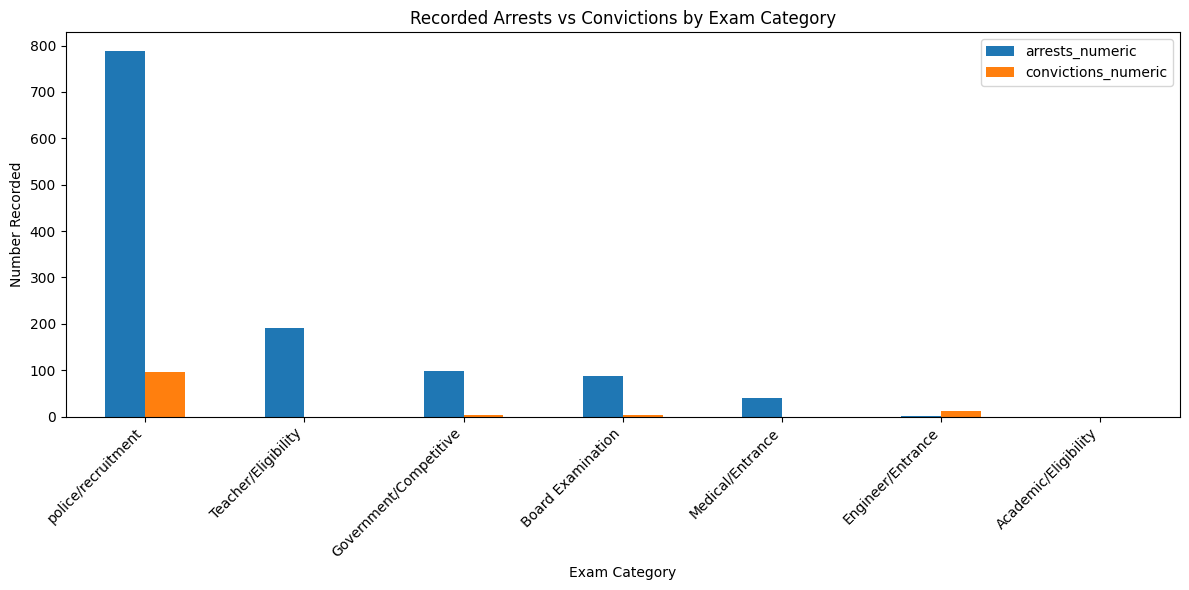

In [131]:
arrests_convictions_by_category.plot(
    kind='bar',
    figsize=(12,6)
)

plt.title('Recorded Arrests vs Convictions by Exam Category')
plt.xlabel('Exam Category')
plt.ylabel('Number Recorded')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [132]:
### Police/Recruitment incidents accounted for the largest number of both recorded arrests (789) and recorded convictions (96). 
### However, conviction data was missing for most incidents, so the arrest and conviction totals should be interpreted as recorded counts 
### rather than a direct measure of legal outcomes.

### What actions were taken in response to reported paper-leak incidents?

In [133]:
df_analysis['action_taken'].value_counts(dropna=False)

action_taken
Arrests-FIR + Probe (CBI/SIT)                              19
Exam cancelled + Arrests-FIR                               12
Arrests-FIR                                                11
Retest + Arrests-FIR                                        5
Exam cancelled + Retest + Arrests-FIR                       4
None reported                                               4
Exam cancelled + Arrests-FIR + Probe (CBI/SIT)              3
Probe                                                       3
Arrests-FIR + Probe                                         3
Exam cancelled+Arrests-FIR                                  3
Exam cancelled + Arrests-FIR + Retest                       3
Arrests-FIR + Probe (SIT)                                   2
Exam cancelled + Retest                                     2
Exam cancelled + Probe (CBI/SIT)                            2
Exam cancelled                                              2
Arrests-FIR+Probe (CBI/SIT)                              

In [134]:
df_analysis['arrests_fir'] = df_analysis['action_taken'].str.contains(
    'arrests-FIR',
    case=False,
    na=False
)

df_analysis['exam_cancelled'] = df_analysis['action_taken'].str.contains(
    'exam cancelled',
    case=False,
    na=False
)

df_analysis['retest'] =  df_analysis['action_taken'].str.contains(
    'retest',
    case=False,
    na=False
)

df_analysis['probe'] = df_analysis['action_taken'].str.contains(
    'Probe',
    case=False,
    na=False
)

In [135]:
print(df_analysis[
    ['arrests_fir','exam_cancelled','retest','probe']
])

     arrests_fir  exam_cancelled  retest  probe
0           True            True   False   True
1           True           False    True  False
2           True           False   False   True
3           True           False   False   True
4           True           False   False   True
..           ...             ...     ...    ...
105         True            True    True  False
106         True           False   False   True
107         True            True    True   True
108        False           False   False  False
109         True           False   False  False

[103 rows x 4 columns]


In [136]:
action_count = pd.Series({
    'Arrests/FIR': df_analysis['arrests_fir'].sum(),
    'Exam Cancelled': df_analysis['exam_cancelled'].sum(),
    'Retest': df_analysis['retest'].sum(),
    'Probe/Investigation': df_analysis['probe'].sum()
})

print(action_count.sort_values(ascending=False))

Arrests/FIR            84
Probe/Investigation    55
Exam Cancelled         51
Retest                 21
dtype: int64


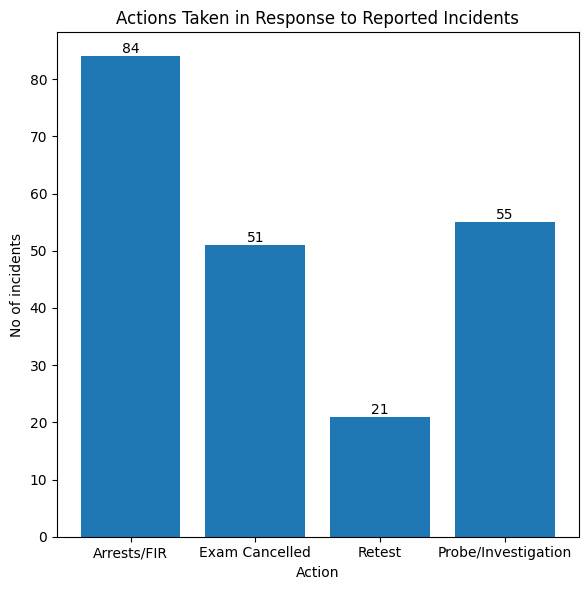

In [137]:
plt.figure(figsize=(6,6))
bars = plt.bar(
    action_count.index,
    action_count.values
)

plt.title('Actions Taken in Response to Reported Incidents')
plt.xlabel('Action')
plt.ylabel('No of incidents')
plt.xticks(rotation=0, ha='center')
for bar in bars:
    plt.text(
        bar.get_x() +bar.get_width()/2,
        bar.get_height(),
        int(bar.get_height()),
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

In [138]:
## Arrests/FIR was the most frequently recorded response action, appearing in 84 incidents, followed by probes/investigations in 55 incidents and exam cancellations in 51 incidents. 
## Retests were recorded in 21 incidents. Since incidents can involve multiple actions, these categories are not mutually exclusive.

### Did the types of actions taken vary across exam categories?

In [139]:
actions_by_category = (
    df_analysis.groupby('exam_category')[
         ['arrests_fir', 'exam_cancelled', 'retest', 'probe']
    ]
    .sum()
)

print(actions_by_category)

                        arrests_fir  exam_cancelled  retest  probe
exam_category                                                     
Academic/Eligibility              0               1       0      1
Board Examination                 8               2       4      2
Engineer/Entrance                 2               0       1      1
Government/Competitive           14              10       3     12
Medical/Entrance                 13               4       4      7
Teacher/Eligibility              10               6       2      6
police/recruitment               37              28       7     26


In [140]:
response_rates = (
    actions_by_category.div(df_analysis['exam_category'].value_counts(),axis=0)
    *100
)

print(response_rates.round(2))

                        arrests_fir  exam_cancelled  retest   probe
exam_category                                                      
Academic/Eligibility           0.00          100.00    0.00  100.00
Board Examination             88.89           22.22   44.44   22.22
Engineer/Entrance            100.00            0.00   50.00   50.00
Government/Competitive        77.78           55.56   16.67   66.67
Medical/Entrance              86.67           26.67   26.67   46.67
Teacher/Eligibility           83.33           50.00   16.67   50.00
police/recruitment            80.43           60.87   15.22   56.52


In [141]:
### Response patterns varied across examination categories. 
### Arrests/FIR were recorded across most major categories at rates above 75%, 
### while Police/Recruitment incidents showed the highest cancellation rate among the larger categories (60.87%). 
### Government/Competitive examinations had a relatively high investigation rate (66.67%). 
### However, percentages for smaller categories should be interpreted cautiously because they are based on very few incidents.

### Which incidents affected the largest number of aspirants?

In [142]:
df_analysis['aspirants_affected'].dtype

dtype('O')

In [143]:
df_analysis['aspirants_affected'].describe()

count         42.0
unique        38.0
top       100000.0
freq           4.0
Name: aspirants_affected, dtype: float64

In [144]:
df_analysis['aspirants_affected_numeric'] = pd.to_numeric(
    df_analysis['aspirants_affected'],
    errors='coerce'
)

In [145]:
df_analysis['aspirants_affected_numeric'].describe()

count    4.200000e+01
mean     5.102754e+05
std      9.118628e+05
min      1.140000e+02
25%      5.775000e+04
50%      1.246030e+05
75%      5.625000e+05
max      4.800000e+06
Name: aspirants_affected_numeric, dtype: float64

In [146]:
top_affected_incidents = (
    df_analysis[
        ['incident_id', 'date', 'area_clean', 'exam_name', 'aspirants_affected_numeric']
    ]
    .sort_values(
        'aspirants_affected_numeric',
        ascending=False
    )
)

print(top_affected_incidents.head(10))

    incident_id                 date      area_clean  \
89      PL-0090  2024-02-17 00:00:00   Uttar Pradesh   
92      PL-0093  2024-05-05 00:00:00       All India   
107     PL-0108  2026-05-03 00:00:00       All India   
57      PL-0058  2021-11-28 00:00:00   Uttar Pradesh   
56      PL-0057  2021-10-23 00:00:00       Rajasthan   
80      PL-0081  2023-03-15 00:00:00  Madhya Pradesh   
77      PL-0078  2023-01-29 00:00:00         Gujarat   
93      PL-0094  2024-06-18 00:00:00       All India   
85      PL-0086  2023-08-17 00:00:00     Maharashtra   
48      PL-0049  2021-01-09 00:00:00         Haryana   

                                             exam_name  \
89           UP Police Constable Recruitment Exam 2024   
92                                        NEET-UG 2024   
107                                       NEET-UG 2026   
57   Uttar Pradesh Teacher Eligibility Test (UPTET)...   
56   Patwari (village revenue officer) recruitment ...   
80   MP Patwari Recruitment Exam 20

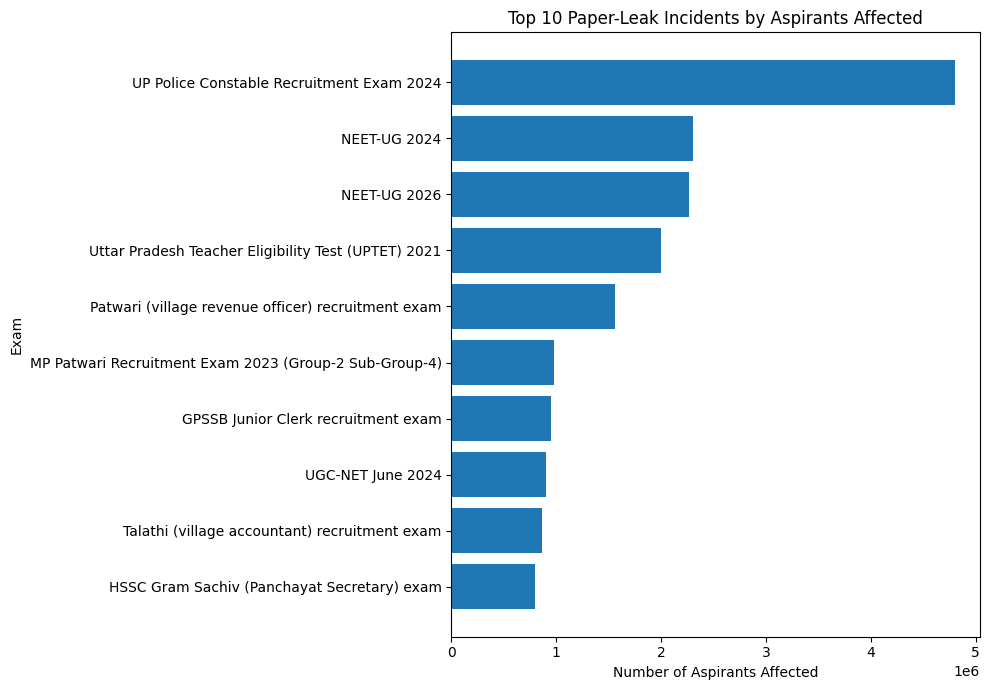

In [147]:
top_10_affected = top_affected_incidents.head(10).copy()

top_10_affected = top_10_affected.sort_values(
    'aspirants_affected_numeric'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_10_affected['exam_name'],
    top_10_affected['aspirants_affected_numeric']
)

plt.title('Top 10 Paper-Leak Incidents by Aspirants Affected')
plt.xlabel('Number of Aspirants Affected')
plt.ylabel('Exam')

plt.tight_layout()
plt.show()

In [148]:
### These reported incidents affected the largest number of aspirants.

In [149]:
df_analysis.to_csv(
    'paper_leaks_cleaned.csv',
    index=False
)

In [150]:
print(df_analysis.columns.tolist())

['incident_id', 'date', 'era', 'exam_name', 'conducting_body', 'body_type', 'area', 'leak_status', 'action_taken', 'note', 'arrests', 'convictions', 'aspirants_affected', 'linked_deaths', 'deaths_note', 'source_name', 'source_url', 'confidence', 'year', 'area_clean', 'arrests_numeric', 'exam_category', 'convictions_numeric', 'arrests_fir', 'exam_cancelled', 'retest', 'probe', 'aspirants_affected_numeric']


In [151]:
print(df_analysis.shape)

(103, 28)


In [152]:
count_columns = [
    'arrests',
    'convictions',
    'aspirants_affected',
    'linked_deaths',
    'arrests_numeric',
    'convictions_numeric',
    'aspirants_affected_numeric'
]

for col in count_columns:
    df_analysis[col] = df_analysis[col].astype('Int64')

In [153]:
print(df_analysis[count_columns].dtypes)

arrests                       Int64
convictions                   Int64
aspirants_affected            Int64
linked_deaths                 Int64
arrests_numeric               Int64
convictions_numeric           Int64
aspirants_affected_numeric    Int64
dtype: object


In [154]:
df_analysis.to_csv(
    'paper_leaks_cleaned.csv',
    index=False
)